# Assignment 2.

**Sections:**
1. Load and split the data (train / validation / test)
2. Standardize the features
3. Try baseline architectures until one clearly overfits
4. Compare regularization methods (L2, dropout, early stopping) on validation MAE
5. Retrain the best one on train + validation and evaluate on the test set

In [41]:
import matplotlib.pyplot as plt
import numpy as np
from keras.models import Sequential
from keras.layers import Input, Dense
from keras.datasets import california_housing
import keras


## 1. Data and splitting

The "large" version of the **California housing dataset** is used for this assignment.

In [42]:
keras.utils.set_random_seed(21)

In [43]:
(inputs, targets), (x_test, y_test) = california_housing.load_data(version='large', 
                                        test_split=0.2)
print(inputs.shape, targets.shape)
print(x_test.shape, y_test.shape)

(16512, 8) (16512,)
(4128, 8) (4128,)


The dataset consist **20 640 samples** with **8 numerical input features** and **the numerical target variable**.



## 2. Preprocessing

Next we divide the **data samples** into 80/20. **80 %** goes for the training set and **20%** goes for the **validation set**.

In [44]:
# Calculate the split index (80% for training, 20% for validation)
split_index = int(0.8 * len(inputs))

# Extract sets for training and validation
x_train = inputs[:split_index]
y_train = targets[:split_index]

x_val = inputs[split_index:]
y_val = targets[split_index:]

print(f"Training set shape: {x_train.shape}")
print(f"Validation set shape: {x_val.shape}")

Training set shape: (13209, 8)
Validation set shape: (3303, 8)



Features are standardized using the mean and standard deviation of the **training set only**.

This ensures that there are no information leaks from the validation or test data. The target (house value) is divided by 1e5, so MAE values are in units of $100 000.

In [45]:

mean = x_train.mean(axis=0) # mean and standard deviation computed from training set only
std = x_train.std(axis=0)
x_train -= mean
x_train /= std
x_test -= mean
x_test /= std
x_val -= mean
x_val /= std
y_train /= 1e5
y_test /= 1e5
y_val /= 1e5

The preprocess is now completed.

## 3. Baseline architectures

**Model 1** (2 hidden layers, 64 units)

In [46]:
model1 = Sequential([
    Input(shape=(8,)),
    Dense(64, activation='relu'),
    Dense(64, activation='relu'),
    Dense(1)
])

model1.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

history1 = model1.fit(
    x_train, y_train,
    epochs=150,
    batch_size=32,
    validation_data=(x_val, y_val),
    verbose=0
)

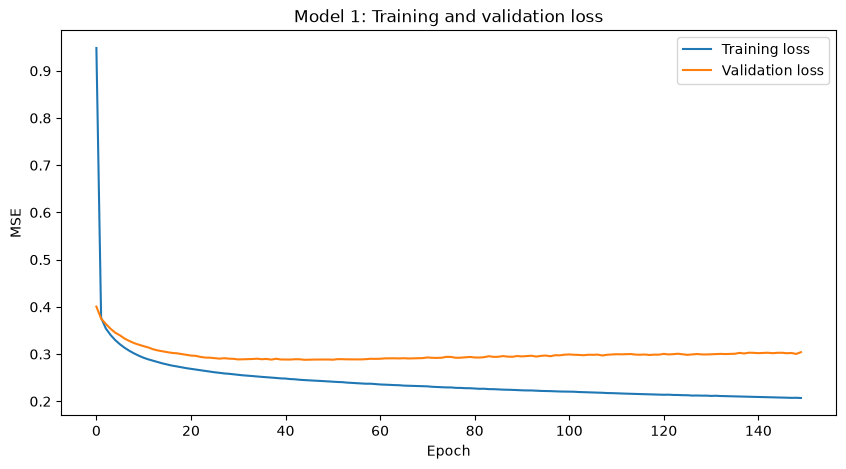

In [47]:
plt.figure(figsize=(10, 5))

plt.plot(history1.history['loss'], label='Training loss')
plt.plot(history1.history['val_loss'], label='Validation loss')

plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.title('Model 1: Training and validation loss')
plt.legend()
plt.show()

The initial model showed relatively stable training and validation losses. The difference between training and validation performance was not particularly large, suggesting that the model did not substantially overfit the training data.

Therefore, I decided to investigate a larger architecture with more parameters.

**Model 2** (4 hidden layers, 256 units)

In [48]:
# define the model architecture
model2 = Sequential([
    Input(shape=(8,)),
    Dense(256, activation='relu'),
    Dense(256, activation='relu'),
    Dense(256, activation='relu'),
    Dense(256, activation='relu'),
    Dense(1)
])

# configure the learning algorithm
model2.compile(optimizer='adam',loss='mse',metrics=['mae'])

In [49]:
history2 = model2.fit(
    x_train, y_train, 
    epochs=150, 
    batch_size=32, 
    validation_data=(x_val, y_val), 
    verbose=1
)


Epoch 1/150
413/413 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 0.5260 - mae: 0.5028 - val_loss: 0.4090 - val_mae: 0.4435
Epoch 2/150
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.3613 - mae: 0.4249 - val_loss: 0.3859 - val_mae: 0.4216
Epoch 3/150
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.3392 - mae: 0.4086 - val_loss: 0.3708 - val_mae: 0.4074
Epoch 4/150
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.3242 - mae: 0.3967 - val_loss: 0.3594 - val_mae: 0.3970
Epoch 5/150
413/413 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 0.3124 - mae: 0.3877 - val_loss: 0.3502 - val_mae: 0.3907
Epoch 6/150
413/413 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 0.3043 - mae: 0.3813 - val_loss: 0.3447 - val_mae: 0.3865
Epoch 7/150
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.2975 - mae: 0.3768 - val_loss: 0.3312 - val_mae: 0.3772
Epoch 8/150
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.2900 - mae: 0.3714 - val_loss: 0.3355 - val_mae: 0.3804
Epoch 9/150
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/

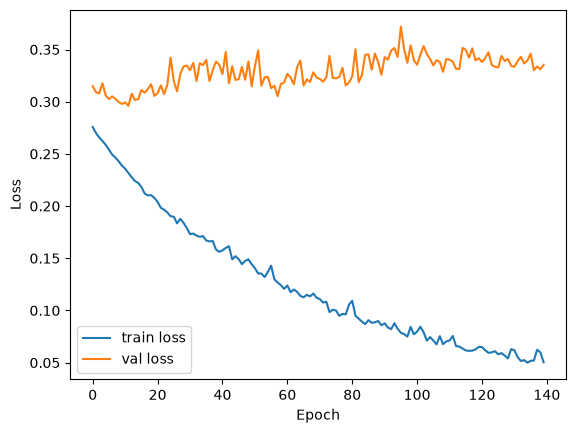

In [50]:

plt.plot(history2.history['loss'][10:], label='train loss')
plt.plot(history2.history['val_loss'][10:], label='val loss')
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

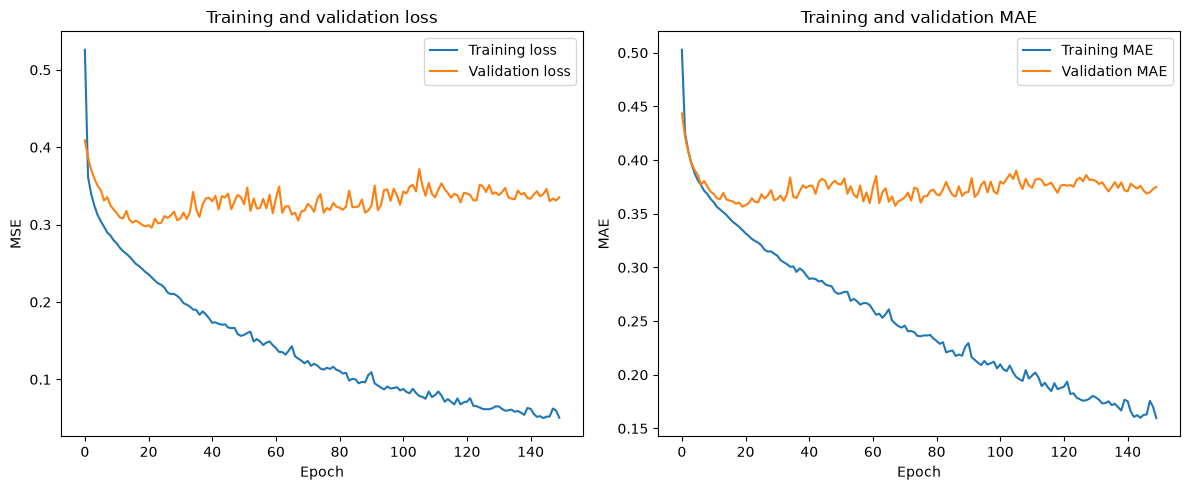

In [51]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history2.history['loss'], label='Training loss')
plt.plot(history2.history['val_loss'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.title('Training and validation loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history2.history['mae'], label='Training MAE')
plt.plot(history2.history['val_mae'], label='Validation MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.title('Training and validation MAE')
plt.legend()

plt.tight_layout()
plt.show()

In [52]:
best_val_mae = min(history2.history['val_mae'])
print("Best validation MAE:", best_val_mae)

Best validation MAE: 0.3566010892391205


The larger `model2` achieved considerably lower training error compared with the initial model. However, the validation loss initially descreased and subsequently began increasing, while the training loss continued decreasing.

This shows that the larger model started to overfit the training data.

Therefore, this architecture will be used as a starting point for when investigating different **regularization techniques**.

## 4. Regularization

All 3 experiment methods use the Model 2 architecture, so the effect of each method can be compared directly.

### 4.1 L2 regularization

In [53]:
from keras.regularizers import l2

model_l2 = Sequential([
    Input(shape=(8,)),
    Dense(256, activation='relu', kernel_regularizer=l2(0.001)),
    Dense(256, activation='relu', kernel_regularizer=l2(0.001)),
    Dense(256, activation='relu', kernel_regularizer=l2(0.001)),
    Dense(256, activation='relu', kernel_regularizer=l2(0.001)),
    Dense(1)
])


Penalty of 0.001 on the weights of every hidden layer.

In [54]:
model_l2.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

In [55]:
history_l2 = model_l2.fit(
    x_train, y_train,
    epochs=150,
    batch_size=32,
    validation_data=(x_val, y_val),
    verbose=0
)

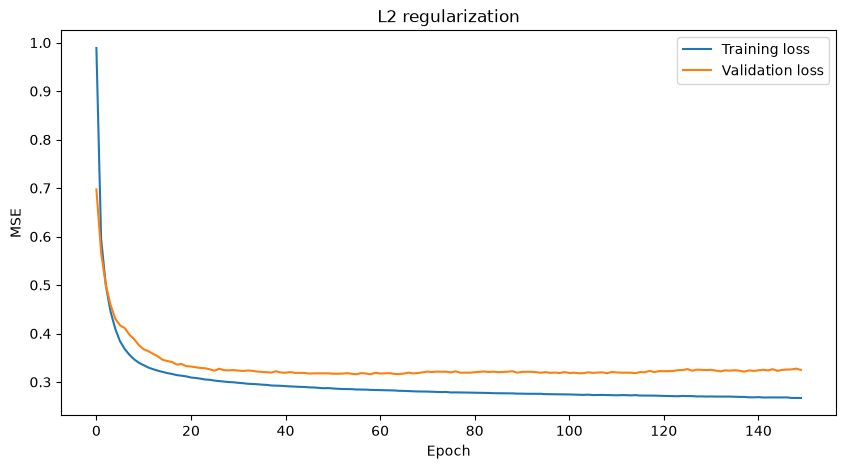

Best validation MAE (L2): 0.3507736027240753


In [56]:
plt.figure(figsize=(10, 5))

plt.plot(history_l2.history['loss'], label='Training loss')
plt.plot(history_l2.history['val_loss'], label='Validation loss')

plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.title('L2 regularization')
plt.legend()
plt.show()

best_l2 = min(history_l2.history['val_mae'])
print("Best validation MAE (L2):", best_l2)

### 5.2 Dropout

Dropout rate 0.2 after the first three hidden layers (not the last one). 

In [57]:
from keras.layers import Dropout

model_dropout = Sequential([
    Input(shape=(8,)),
    Dense(256, activation='relu'),
    Dropout(0.2),
    Dense(256, activation='relu'),
    Dropout(0.2),
    Dense(256, activation='relu'),
    Dropout(0.2),
    Dense(256, activation='relu'),
    Dense(1)
])

model_dropout.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

history_dropout = model_dropout.fit(
    x_train, y_train,
    epochs=150,
    batch_size=32,
    validation_data=(x_val, y_val),
    verbose=0
)

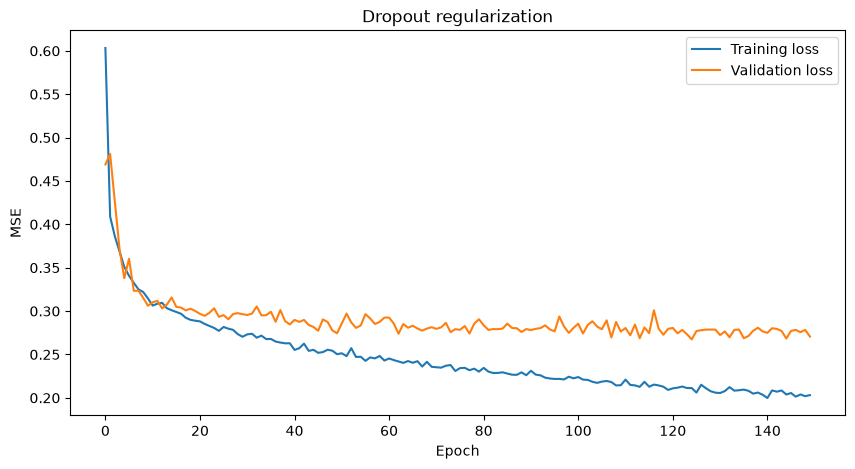

Best validation MAE (Dropout): 0.3335278332233429


In [58]:
plt.figure(figsize=(10, 5))

plt.plot(history_dropout.history['loss'], label='Training loss')
plt.plot(history_dropout.history['val_loss'], label='Validation loss')

plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.title('Dropout regularization')
plt.legend()
plt.show()

best_dropout = min(history_dropout.history['val_mae'])
print("Best validation MAE (Dropout):", best_dropout)

### 5.3 Early stopping



Training stops when validation MAE has not improved for 15 epochs, and the best weights are restored. 

In [59]:
from keras.callbacks import EarlyStopping

model_early = Sequential([
    Input(shape=(8,)),
    Dense(256, activation='relu'),
    Dense(256, activation='relu'),
    Dense(256, activation='relu'),
    Dense(256, activation='relu'),
    Dense(1)
])

model_early.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

early_stopping = EarlyStopping(
    monitor='val_mae',
    patience=15,
    restore_best_weights=True
)

history_early = model_early.fit(
    x_train, y_train,
    epochs=500,
    batch_size=32,
    validation_data=(x_val, y_val),
    callbacks=[early_stopping],
    verbose=0
)

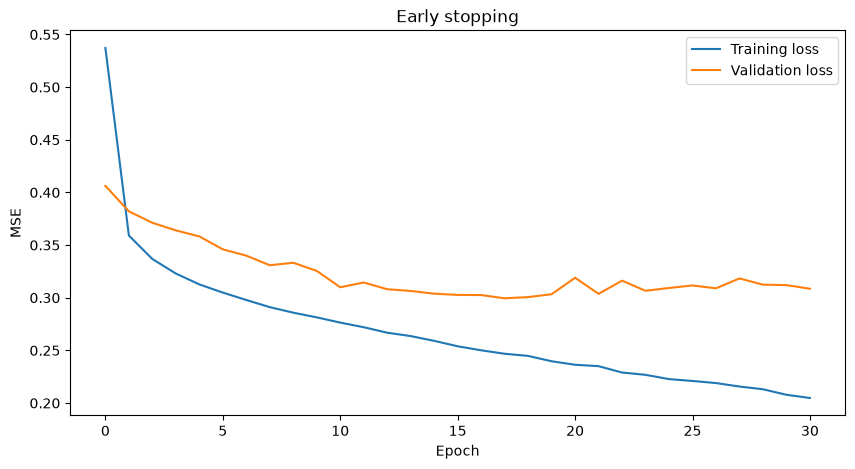

Validation MAE (Early stopping): 0.36050087213516235
Epochs trained: 31


In [60]:
plt.figure(figsize=(10, 5))

plt.plot(history_early.history['loss'], label='Training loss')
plt.plot(history_early.history['val_loss'], label='Validation loss')

plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.title('Early stopping')
plt.legend()
plt.show()

early_loss, early_mae = model_early.evaluate(
    x_val, y_val, verbose=0
)

print("Validation MAE (Early stopping):", early_mae)
print("Epochs trained:", len(history_early.history['loss']))

In [61]:
best_early = min(history_early.history['val_mae'])

results = {
    'L2': best_l2,
    'Dropout': best_dropout,
    'Early stopping': best_early
}

for name, mae in results.items():
    print(f'{name}: {mae:.4f}')

best_method = min(results, key=results.get)

print("\nBest regularization method:", best_method)
print("Best validation MAE:", results[best_method])

L2: 0.3508
Dropout: 0.3335
Early stopping: 0.3605

Best regularization method: Dropout
Best validation MAE: 0.3335278332233429


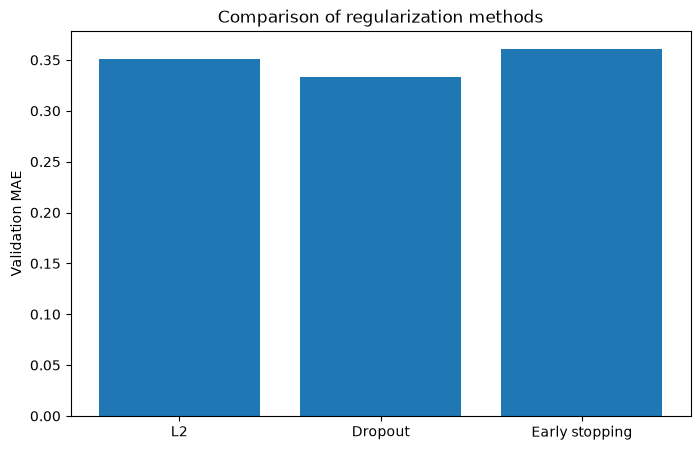

In [62]:
plt.figure(figsize=(8, 5))

plt.bar(results.keys(), results.values())

plt.ylabel('Validation MAE')
plt.title('Comparison of regularization methods')
plt.show()

### Comparison and model selection

I compared the different regularization strategies using their validation MAE.

The method with the lowest validation MAE was selected as the most promising approach. This model will be used for the final training and evaluation.

The test dataset has not been used during model selection.

## 6. Final training and testing

After comparing the regularization techniques, I select the model with the lowest validation MAE.

I combine the training and validation datasets and train a new model from scratch using the selected architecture and regularization technique.

The number of training epochs is determined from the validation experiments.

Finally, I evaluate the model on the test dataset, which has not been used during training or model selection.

In [63]:
x_train_full = np.concatenate([x_train, x_val])
y_train_full = np.concatenate([y_train, y_val])

In [64]:
from keras.regularizers import l2

def build_final_model(method):

    model = Sequential()
    model.add(Input(shape=(8,)))

    if method == 'L2':
        for _ in range(4):
            model.add(Dense(
                256,
                activation='relu',
                kernel_regularizer=l2(0.001)
            ))

    elif method == 'Dropout':
        for _ in range(4):
            model.add(Dense(256, activation='relu'))
            if _ < 3:
                model.add(Dropout(0.2))

    elif method == 'Early stopping':
        for _ in range(4):
            model.add(Dense(256, activation='relu'))

    model.add(Dense(1))

    model.compile(
        optimizer='adam',
        loss='mse',
        metrics=['mae']
    )

    return model

In [65]:
histories = {
    'L2': history_l2,
    'Dropout': history_dropout,
    'Early stopping': history_early
}

best_epoch = np.argmin(
    histories[best_method].history['val_mae']
) + 1

print("Selected method:", best_method)
print("Selected epochs:", best_epoch)

Selected method: Dropout
Selected epochs: 145


In [66]:
final_model = build_final_model(best_method)

final_history = final_model.fit(
    x_train_full,
    y_train_full,
    epochs=best_epoch,
    batch_size=32,
    verbose=1
)

Epoch 1/145
516/516 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.5813 - mae: 0.5334
Epoch 2/145
516/516 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.4130 - mae: 0.4541
Epoch 3/145
516/516 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.3825 - mae: 0.4347
Epoch 4/145
516/516 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.3604 - mae: 0.4205
Epoch 5/145
516/516 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.3471 - mae: 0.4115
Epoch 6/145
516/516 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.3367 - mae: 0.4049
Epoch 7/145
516/516 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.3320 - mae: 0.4018
Epoch 8/145
516/516 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.3269 - mae: 0.3991
Epoch 9/145
516/516 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.3224 - mae: 0.3963
Epoch 10/145
516/516 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.3200 - mae: 0.3938
Epoch 11/145
516/516 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.3147 - mae: 0.3898
Epoch 12/145
516/516 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.3113 - mae: 0.3878
Epoch 13/145


In [69]:
test_loss, test_mae = final_model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print("Final test loss:", test_loss)
print("Final test MAE:", test_mae)
print("Best validation MAE:", results[best_method])
print(f"Test MAE: {test_mae:.4f} (x1e5) = ${test_mae * 1e5:,.0f}")

Final test loss: 0.27102744579315186
Final test MAE: 0.3372765779495239
Best validation MAE: 0.3335278332233429
Test MAE: 0.3373 (x1e5) = $33,728


### Result

The final model reaches a test MAE of around 0.337, which is about $33,728. The best validation MAE was around 0.334, so the test result is close to it. This suggests the model generalizes well to unseen data.